<a href="https://colab.research.google.com/github/ikwak2/bio_sig_class/blob/main/01_signal_processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 실습 1. ECG 신호처리와 피처 엔지니어링

**학습 목표**
1. 샘플링 주파수·단위·저장 해상도를 구분한다.
2. 오프라인 필터링 후 PSD와 STFT를 비교한다.
3. 진폭·분포·주파수·웨이블릿·박동 간격·형태 특징을 계산한다.
4. 구간별 특징을 ML 입력 표로 모으고, 정규화와 데이터 누수를 이해한다.

기존 신호처리 실습 약 12분 + 특징 추출 확장 약 35–50분을 예상합니다. 시간은 설명과 다운로드 환경에 따라 달라집니다.

데이터: MIT-BIH Arrhythmia Database v1.0.0, Moody & Mark, DOI: [10.13026/C2F305](https://doi.org/10.13026/C2F305).
데이터는 원 제공처의 이용 조건을 따릅니다. 이 실습은 특징 계산을 배우는 교육 자료이며 진단 도구가 아닙니다.


In [ ]:
%pip install -q wfdb

In [ ]:
from pathlib import Path
import hashlib
import json
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import signal
from sklearn.metrics import roc_auc_score, average_precision_score, balanced_accuracy_score
import wfdb

ROOT = Path.cwd()
DATA = ROOT / 'data' / 'mitdb'
RESULTS = ROOT / 'results'
# These eight records are different subjects. When expanding, group 201 and 202 together.
SPLITS = {
    'train': ['100', '101', '103', '106', '108', '119'],
    'val': ['105', '112', '200'],
    'test': ['117', '203', '208'],
}
FS = 360

def download_record(record):
    if record not in sum(SPLITS.values(), []):
        raise ValueError('Record not included in the teaching manifest')
    DATA.mkdir(parents=True, exist_ok=True)
    for ext in ['hea','dat','atr']:
        dest = DATA / f'{record}.{ext}'
        if not dest.exists():
            url = f'https://physionet.org/files/mitdb/1.0.0/{dest.name}'
            tmp = dest.with_suffix(dest.suffix+'.part')
            try:
                with urllib.request.urlopen(url, timeout=90) as src:
                    tmp.write_bytes(src.read())
                tmp.replace(dest)
            finally:
                tmp.unlink(missing_ok=True)
    return DATA / record

def read_record(record):
    p=download_record(record)
    rec=wfdb.rdrecord(str(p))
    ann=wfdb.rdann(str(p),'atr')
    assert rec.fs == FS
    lead = rec.sig_name.index('MLII') if 'MLII' in rec.sig_name else 0
    return rec,ann,lead



필터는 0.5–40 Hz, 4차 Butterworth와 `sosfiltfilt`입니다.

In [ ]:
def filtered(x):
    sos = signal.butter(
        4,
        [0.5, 40],
        btype='bandpass',
        fs=FS,
        output='sos'
    )
    return signal.sosfiltfilt(sos, x)

360 ['MLII', 'V1'] ['mV', 'mV'] (650000, 2)


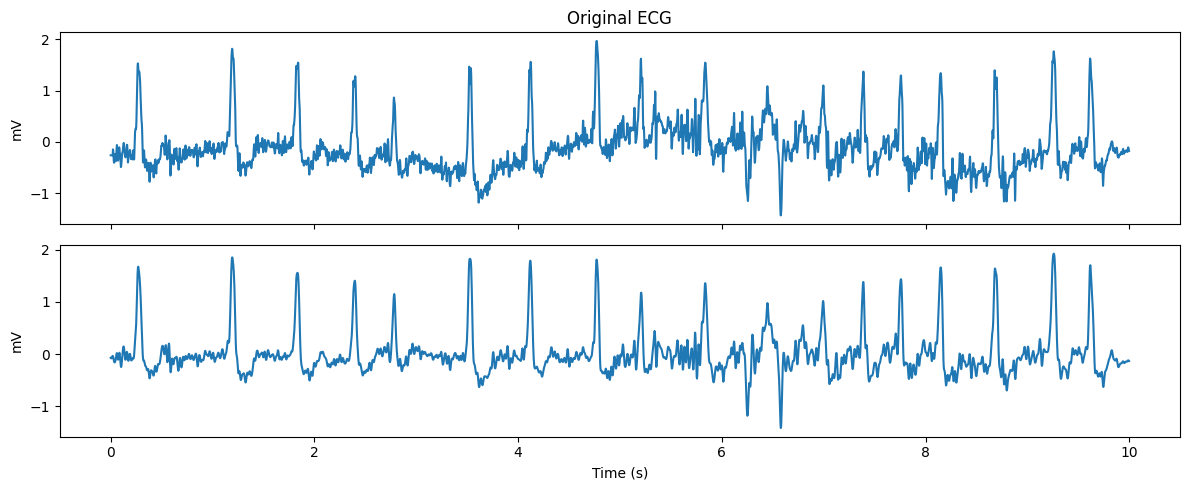

In [ ]:
rec, ann, lead = read_record('203')
print(rec.fs, rec.sig_name, rec.units, rec.p_signal.shape)
x = rec.p_signal[:,lead]
y = filtered(x)
t = np.arange(10*FS)/FS
fig, ax = plt.subplots(2,1,figsize=(12,5),sharex=True)
ax[0].plot(t,x[:len(t)]); ax[0].set_ylabel(rec.units[lead]); ax[0].set_title('Original ECG')
ax[1].plot(t,y[:len(t)]); ax[1].set_xlabel('Time (s)'); ax[1].set_ylabel(rec.units[lead])
plt.tight_layout(); plt.show()

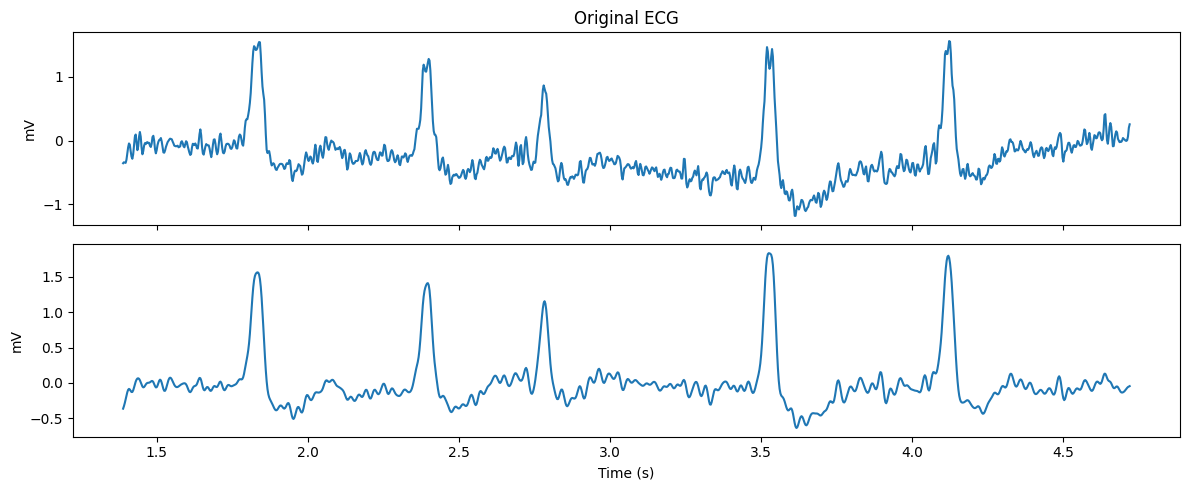

In [ ]:
fig, ax = plt.subplots(2,1,figsize=(12,5),sharex=True)
ax[0].plot(t[500:1700],x[500:1700]); ax[0].set_ylabel(rec.units[lead]); ax[0].set_title('Original ECG')
ax[1].plot(t[500:1700],y[500:1700]); ax[1].set_xlabel('Time (s)'); ax[1].set_ylabel(rec.units[lead])
plt.tight_layout(); plt.show()

## STFT 피쳐 그림



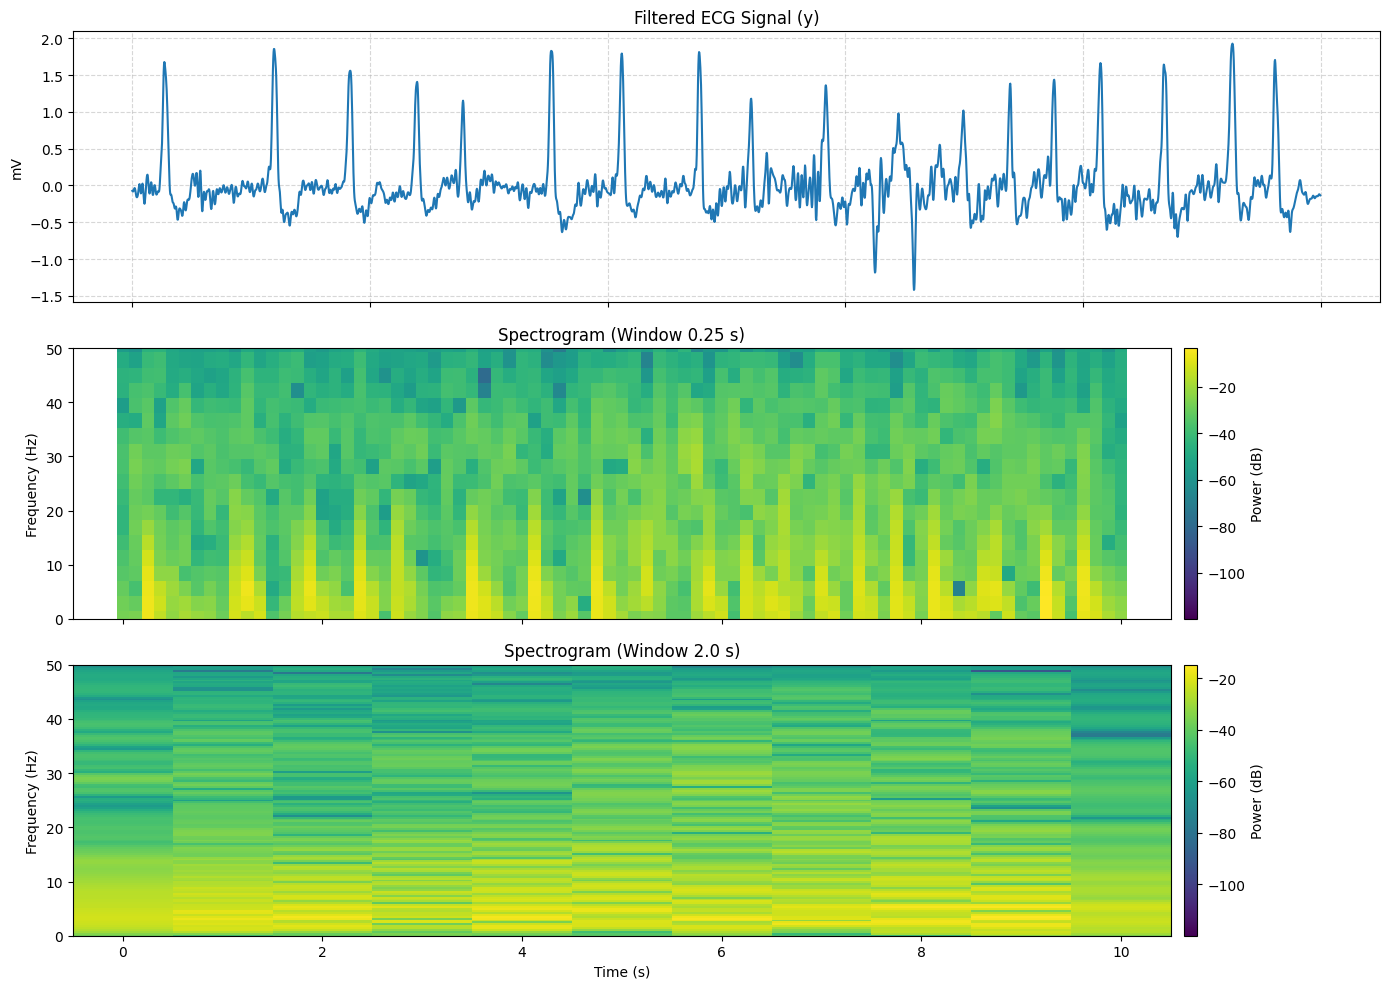

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# 203 기록의 필터링된 신호 y에서 처음 10초 구간을 시각화합니다.
t_10 = np.arange(10 * FS) / FS
y_10 = y[:len(t_10)]

# 시간축을 완벽히 맞추기 위해 sharex=True를 지원하도록 3행 1열 구조로 배치합니다.
fig, axs = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

# 1. 상단: 필터링된 ECG 신호 y (Time Domain)
axs[0].plot(t_10, y_10, color='tab:blue')
axs[0].set_title('Filtered ECG Signal (y)')
axs[0].set_ylabel('mV')
axs[0].grid(True, linestyle='--', alpha=0.5)

# 2. 중간: Window 0.25s 스펙트로그램
window_s1 = 0.25
nperseg1 = int(window_s1 * FS)
f1, t1, z1 = signal.stft(y_10, fs=FS, nperseg=nperseg1, noverlap=int(nperseg1 * 0.5), nfft = 128)
im1 = axs[1].pcolormesh(t1, f1, 20 * np.log10(np.abs(z1) + 1e-6), shading='auto', cmap='viridis')
axs[1].set_ylim(0, 50)
axs[1].set_title(f'Spectrogram (Window {window_s1} s)')
axs[1].set_ylabel('Frequency (Hz)')
fig.colorbar(im1, ax=axs[1], label='Power (dB)', pad=0.01)

# 3. 하단: Window 2.0s 스펙트로그램
window_s2 = 2.0
nperseg2 = int(window_s2 * FS)
f2, t2, z2 = signal.stft(y_10, fs=FS, nperseg=nperseg2, noverlap=int(nperseg2 * 0.5), nfft = 1024)
im2 = axs[2].pcolormesh(t2, f2, 20 * np.log10(np.abs(z2) + 1e-6), shading='auto', cmap='viridis')
axs[2].set_ylim(0, 50)
axs[2].set_title(f'Spectrogram (Window {window_s2} s)')
axs[2].set_xlabel('Time (s)')
axs[2].set_ylabel('Frequency (Hz)')
fig.colorbar(im2, ax=axs[2], label='Power (dB)', pad=0.01)

plt.tight_layout()
plt.show()

## 1. 파형을 특징으로 바꾸기

30초를 360 Hz로 측정하면 한 채널에서 **10,800개(30*360) 진폭 값**이 생깁니다. 이 구간에서 RMS·주파수별 파워·박동 간격 같은 숫자를 계산하면 한 행의 특징 벡터가 됩니다.

| 관점 | 대표 특징 | 질문 |
|---|---|---|
| 진폭·분포 | RMS, 표준편차, IQR, 왜도, 첨도 | 얼마나 크게, 비대칭적으로 흔들리는가? |
| 변화·반복성 | 차분, Hjorth, 자기상관 | 얼마나 빨리 변하고 반복되는가? |
| 주파수 | 대역 파워, 파워 비율, 엔트로피 | 어떤 진동 속도에 파워가 집중되는가? |
| 시간–주파수 | STFT·웨이블릿 성분의 통계 | 빠르거나 느린 변화가 언제 나타나는가? |
| 박동·형태 | RR 간격, RMSSD, 박동 유사도 | 박동의 간격과 모양은 얼마나 일정한가? |

여기서 **수작업 특징**이란 사람이 계산법을 설계한다는 뜻입니다. 계산은 코드가 자동으로 수행합니다.

앞부분의 `203`은 파형을 보는 예시입니다. 아래 설계·비교 실습은 훈련 목록의 `100`으로 바꿉니다. 시험 기록을 보고 특징과 임계값을 반복 선택하면 평가에 누수가 생길 수 있습니다.

In [ ]:
from scipy import stats
from scipy.integrate import trapezoid
from wfdb import processing
import pywt
from IPython.display import display

DEMO_RECORD = '100'
DEMO_SECONDS = 180
demo_rec, demo_ann, demo_lead = read_record(DEMO_RECORD)
demo_fs = float(demo_rec.fs)
demo_unit = demo_rec.units[demo_lead]
demo_raw = np.asarray(demo_rec.p_signal[:, demo_lead], dtype=float)
# 기록 전체를 먼저 필터링하고 잘라 창마다 필터 끝부분 왜곡이 반복되는 것을 줄입니다.
demo_filtered_full = filtered(demo_raw)
demo_ecg = demo_filtered_full[:int(DEMO_SECONDS * demo_fs)]
demo_time = np.arange(len(demo_ecg)) / demo_fs
assert demo_unit == 'mV', f'이 예시는 mV를 가정합니다. 현재 단위: {demo_unit}'
print(f'record={DEMO_RECORD}, lead={demo_rec.sig_name[demo_lead]}, fs={demo_fs:g} Hz')
print(f'unit={demo_unit}, duration={len(demo_ecg)/demo_fs:.1f} s')

record=100, lead=MLII, fs=360 Hz
unit=mV, duration=180.0 s


### 1-1. ADC bit depth와 분석 자료형은 다르다

`wfdb.rdrecord()`의 `p_signal`은 gain·baseline을 적용한 **물리 단위 값**입니다. `float64`라는 메모리 자료형이 원래 장비가 64 bit ADC였다는 뜻은 아닙니다.

MIT-BIH는 360 Hz, 10 mV 범위에서 11 bit 해상도로 디지털화한 데이터입니다. 11 bit의 단계 수는 $2^{11}=2048$임.

WFDB의 `fmt='212'`는 **저장 인코딩 이름**입니다. 원래 ADC 해상도와 같은 의미가 아닙니다. 물리값 변환은 다음과 같습니다.

$$x_{physical}=\frac{x_{digital}-baseline}{adc\_gain}.$$

자료형·저장 형식·ADC 해상도·단위를 각각 확인하는 습관을 갖습니다.

In [ ]:
display(pd.DataFrame({
    'lead': demo_rec.sig_name,
    'unit': demo_rec.units,
    'storage_fmt': demo_rec.fmt,
    'adc_resolution_bits': demo_rec.adc_res,
    'adc_gain_counts_per_unit': demo_rec.adc_gain,
    'baseline': demo_rec.baseline,
}))
print('p_signal dtype:', demo_rec.p_signal.dtype)
print('11-bit, 10-mV 범위의 이론상 간격:', 10 / 2**11, 'mV')

,lead,unit,storage_fmt,adc_resolution_bits,adc_gain_counts_per_unit,baseline
0,MLII,mV,212,11,200.0,1024
1,V5,mV,212,11,200.0,1024


p_signal dtype: float64
11-bit, 10-mV 범위의 이론상 간격: 0.0048828125 mV


In [ ]:
demo_raw

array([-0.145, -0.145, -0.145, ..., -0.675, -0.765, -1.28 ],
      shape=(650000,))

In [ ]:
demo_raw * 200 + 1024

array([995., 995., 995., ..., 889., 871., 768.], shape=(650000,))

## 2. 시간영역 특징: 크기, 분포, 변화

한 구간의 신호를 $x_1,\ldots,x_N$, 평균을 $\mu$라고 합시다.

$$\mathrm{RMS}=\sqrt{\frac1N\sum_i x_i^2},\qquad
\mathrm{Var}(x)=\frac1N\sum_i(x_i-\mu)^2.$$

- **평균:** 기준 수준입니다. 고역통과 필터 이후에는 0에 가까워질 수 있습니다.
- **표준편차·RMS:** 흔들림 또는 전체 진폭의 크기입니다. $\mathrm{RMS}^2=\mu^2+\mathrm{Var}(x)$이므로 중복 정보가 있습니다.
- **IQR:** 75% 분위수에서 25% 분위수를 뺀 값으로 극단값에 덜 민감합니다.
- **왜도:** 진폭 분포의 비대칭입니다. 전극 방향이 뒤집혀도 부호가 바뀔 수 있습니다.
- **초과첨도:** 표준화한 4차 모멘트에서 3을 뺀 값입니다. 드문 큰 진폭에 민감하며 정규분포의 기준값은 0입니다.
- **평균 절대 차분:** 이웃한 표본이 얼마나 다르게 움직이는지 요약합니다. 샘플링 주파수에 영향을 받습니다.
- **1초 지연 자기상관:** 1초 전후 파형의 유사도입니다. 피크가 반복되는 주기를 살펴볼 단서지만, 이것만으로 심박수나 질환을 확정할 수 없습니다.

**Hjorth 지표**는 다음과 같습니다. $\dot x$는 시간 간격을 반영한 차분입니다.

$$A=\mathrm{Var}(x),\qquad M=\sqrt{\frac{\mathrm{Var}(\dot x)}{\mathrm{Var}(x)}},\qquad
C=\frac{M(\dot x)}{M(x)}.$$

Activity는 크기, Mobility는 변화 속도, Complexity는 변화 속도의 변화 정도를 요약합니다. Complexity는 인지능력 점수가 아닙니다. 상수 신호에서는 일부 비율을 정의할 수 없으므로 `NaN`으로 둡니다.

In [ ]:
def validate_segment(segment, fs):
    z = np.asarray(segment, dtype=float)
    if z.ndim != 1 or not np.isfinite(z).all():
        raise ValueError('유한한 값만 포함한 1차원 신호가 필요합니다.')
    if not np.isfinite(fs) or fs <= 0 or len(z) < max(4, int(2 * fs)):
        raise ValueError('양의 fs와 최소 2초 신호가 필요합니다.')
    return z

def time_features(segment, fs):
    z = validate_segment(segment, fs)
    v = float(np.var(z))
    dz = np.diff(z) * fs
    ddz = np.diff(dz) * fs
    vd, vdd = float(np.var(dz)), float(np.var(ddz))
    mobility = np.sqrt(vd / v) if v > 1e-24 else np.nan
    complexity = (np.sqrt(vdd / vd) / mobility
                  if vd > 1e-24 and np.isfinite(mobility) and mobility > 0
                  else np.nan)
    lag = int(round(fs))
    a, b = z[:-lag], z[lag:]
    ac = (float(np.corrcoef(a, b)[0, 1])
          if np.std(a) > 1e-12 and np.std(b) > 1e-12 else np.nan)
    return {
        'mean_mV': float(np.mean(z)),
        'std_mV': float(np.std(z)),
        'rms_mV': float(np.sqrt(np.mean(z**2))),
        'iqr_mV': float(np.percentile(z, 75) - np.percentile(z, 25)),
        'peak_to_peak_mV': float(np.ptp(z)),
        'skewness': float(stats.skew(z, bias=False)) if v > 1e-24 else np.nan,
        'excess_kurtosis': float(stats.kurtosis(z, fisher=True, bias=False)) if v > 1e-24 else np.nan,
        'mean_abs_diff_mV': float(np.mean(np.abs(np.diff(z)))),
        'hjorth_activity_mV2': v,
        'hjorth_mobility_per_s': float(mobility),
        'hjorth_complexity': float(complexity),
        'autocorr_1s': ac,
    }

first30 = demo_ecg[:int(30 * demo_fs)]
display(pd.Series(time_features(first30, demo_fs), name='첫 30초'))

,첫 30초
mean_mV,-0.000559
std_mV,0.166653
rms_mV,0.166654
iqr_mV,0.089331
peak_to_peak_mV,1.684544
skewness,4.892048
excess_kurtosis,27.961092
mean_abs_diff_mV,0.013137
hjorth_activity_mV2,0.027773
hjorth_mobility_per_s,96.598338


### 실험 A. 진폭을 두 배로 하면 어떤 특징이 변할까?

파형에 2를 곱하면 평균·RMS·표준편차·IQR은 2배, 분산은 4배가 됩니다. 양의 배율만 바꾸었으므로 왜도·첨도·상관·Hjorth Mobility/Complexity는 거의 같습니다.

특징의 수치가 진폭에 민감한지 이해하면 전극 접촉·증폭률 차이가 결과에 끼칠 영향을 예상할 수 있습니다.

,original,amplitude_x2,ratio
mean_mV,-0.00056,-0.00112,2.0
std_mV,0.16665,0.33331,2.0
rms_mV,0.16665,0.33331,2.0
iqr_mV,0.08933,0.17866,2.0
peak_to_peak_mV,1.68454,3.36909,2.0
skewness,4.89205,4.89205,1.0
excess_kurtosis,27.96109,27.96109,1.0
mean_abs_diff_mV,0.01314,0.02627,2.0
hjorth_activity_mV2,0.02777,0.11109,4.0
hjorth_mobility_per_s,96.59834,96.59834,1.0


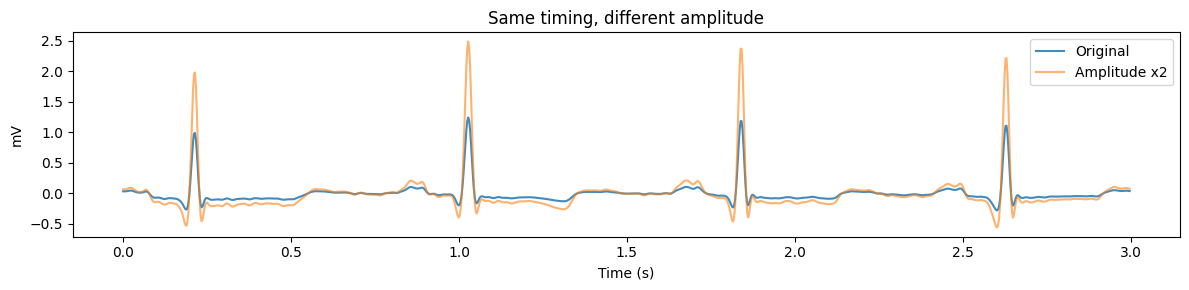

In [ ]:
scale_demo = pd.DataFrame({
    'original': time_features(first30, demo_fs),
    'amplitude_x2': time_features(2 * first30, demo_fs),
})
scale_demo['ratio'] = scale_demo['amplitude_x2'] / scale_demo['original'].replace(0, np.nan)
display(scale_demo.round(5))
fig, ax = plt.subplots(figsize=(12, 3))
show_n = int(3 * demo_fs)
ax.plot(demo_time[:show_n], first30[:show_n], label='Original', alpha=.85)
ax.plot(demo_time[:show_n], 2*first30[:show_n], label='Amplitude x2', alpha=.6)
ax.set(xlabel='Time (s)', ylabel='mV', title='Same timing, different amplitude')
ax.legend(); plt.tight_layout(); plt.show()

## 3. 주파수영역 특징: 대역 파워와 스펙트럼 모양

Welch 방법으로 PSD $P(f)$를 추정합니다. 신호 단위가 mV이면 PSD 단위는 mV²/Hz이며, 주파수 구간을 적분한 파워는 mV²입니다.

$$B_{a:b}=\int_a^b P(f)df,\qquad R_{a:b}=\frac{B_{a:b}}{B_{0.5:40}}.$$

여기서는 ECG 실습용으로 **0.5–5, 5–15, 15–40 Hz**를 나눕니다. ECG 파형의 구성 차이를 보기 위한 구간이며 **EEG의 델타·알파 대역처럼 해석하지 않습니다.**

| 특징 | 의미 |
|---|---|
| 절대 대역 파워 | 각 대역의 진폭 제곱에 관련된 크기 |
| 상대 대역 파워 | 분석 대역 전체에서 차지하는 비중 |
| peak frequency | 분석 대역에서 파워가 가장 큰 주파수 |
| spectral centroid | 파워를 가중치로 한 평균 주파수 |
| spectral edge 95% | 파워의 95%가 그 아래에 놓이는 주파수 |
| normalized spectral entropy | 파워가 특정 빈에 몰리는지, 골고루 퍼지는지 |

엔트로피에서 $p_k=P_k/\sum_jP_j$로 놓고 $H=-\sum_kp_k\log(p_k)/\log K$를 계산합니다. $K$는 주파수 빈의 수입니다. 여기서는 **진폭 분포가 아니라 주파수 파워의 분포**를 사용합니다.

2초 Hann 창, 50% 중첩, Welch 평균을 사용합니다. 빈 간격은 0.5 Hz입니다. 설정이 다르면 특징도 달라지므로 동일하게 유지합니다.

,첫 30초
power_total_0p5_40_mV2,0.027338
power_0p5_5_mV2,0.004347
rel_power_0p5_5,0.159020
power_5_15_mV2,0.012278
rel_power_5_15,0.449114
power_15_40_mV2,0.010713
rel_power_15_40,0.391865
spectral_peak_hz,6.000000
spectral_centroid_hz,13.216884
spectral_edge95_hz,27.500000


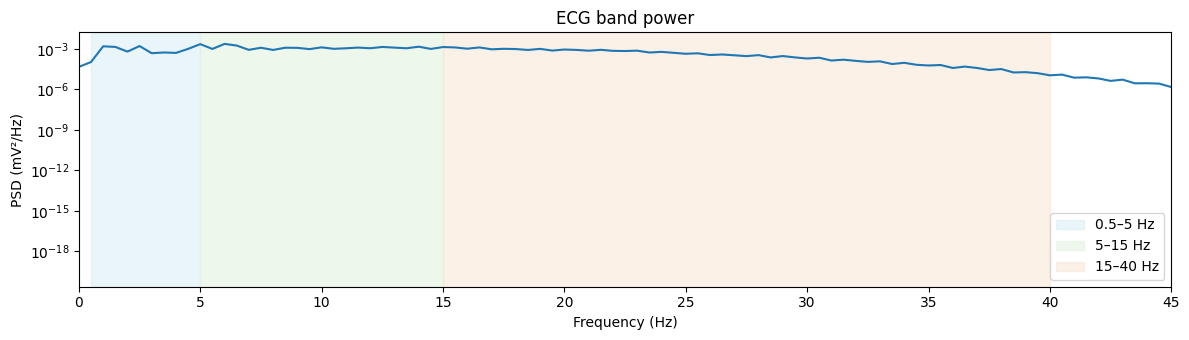

In [ ]:
ECG_BANDS = {'0p5_5': (0.5, 5.0), '5_15': (5.0, 15.0), '15_40': (15.0, 40.0)}

def psd_estimate(segment, fs):
    z = validate_segment(segment, fs)
    if fs <= 80:
        raise ValueError('0.5–40 Hz 특징에는 fs > 80 Hz가 필요합니다.')
    nperseg = min(len(z), int(round(2 * fs)))
    return signal.welch(z, fs=fs, window='hann', nperseg=nperseg,
                        noverlap=nperseg//2, detrend='constant', scaling='density')

def band_integral(freq, power, low, high):
    # 양 끝 경계를 보간해 인접 대역을 적분할 때 빈 경계 누락을 줄입니다.
    inside = (freq > low) & (freq < high)
    ff = np.r_[low, freq[inside], high]
    pp = np.interp(ff, freq, power)
    return float(trapezoid(pp, ff))

def spectral_features(segment, fs):
    freq, power = psd_estimate(segment, fs)
    total = band_integral(freq, power, 0.5, 40)
    out = {'power_total_0p5_40_mV2': total}
    for name, (lo, hi) in ECG_BANDS.items():
        value = band_integral(freq, power, lo, hi)
        out[f'power_{name}_mV2'] = value
        out[f'rel_power_{name}'] = value / total if total > 1e-24 else np.nan
    keep = (freq >= 0.5) & (freq <= 40)
    ff, pp = freq[keep], power[keep]
    if total > 1e-24 and pp.sum() > 0:
        probs = pp / pp.sum()
        positive = probs > 0
        out.update({
            'spectral_peak_hz': float(ff[np.argmax(pp)]),
            'spectral_centroid_hz': float(np.sum(ff * probs)),
            # 균일한 빈의 누적 PSD 합으로 근사합니다.
            'spectral_edge95_hz': float(ff[np.searchsorted(np.cumsum(probs), .95)]),
            'spectral_entropy_norm': float(-np.sum(probs[positive]*np.log(probs[positive])) / np.log(len(probs))),
        })
    else:
        out.update(dict.fromkeys(['spectral_peak_hz', 'spectral_centroid_hz',
                                  'spectral_edge95_hz', 'spectral_entropy_norm'], np.nan))
    return out

display(pd.Series(spectral_features(first30, demo_fs), name='첫 30초'))
freq, power = psd_estimate(first30, demo_fs)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.semilogy(freq, power)
for (name, (lo, hi)), color in zip(ECG_BANDS.items(), ['#d7edf5', '#e1f2dd', '#f8e6d4']):
    ax.axvspan(lo, hi, color=color, alpha=.55, label=f'{lo:g}–{hi:g} Hz')
ax.set(xlim=(0, 45), xlabel='Frequency (Hz)', ylabel='PSD (mV²/Hz)', title='ECG band power')
ax.legend(); plt.tight_layout(); plt.show()

### 실험 B. 같은 RMS를 가진 단순한 파형과 넓은 대역 신호

10 Hz 사인파와 고정 seed의 백색잡음을 각각 평균 0, 표준편차 1로 맞춥니다. 두 신호의 진폭 규모는 비슷하지만 파워 분포는 다릅니다.

예상: 사인파는 10 Hz 근처에 파워가 몰리고, 잡음은 여러 주파수에 퍼집니다. 따라서 스펙트럼 엔트로피가 달라집니다. **높은 엔트로피를 더 건강하거나 더 좋은 신호라고 해석하면 안 됩니다.** 아래 데이터는 실제 환자 신호가 아닙니다.

,rms_unitless,hjorth_mobility_per_s,spectral_peak_hz,spectral_entropy_norm
10-Hz sine,1.0,62.749273,10.0,0.197982
White noise,1.0,506.069675,34.5,0.996834


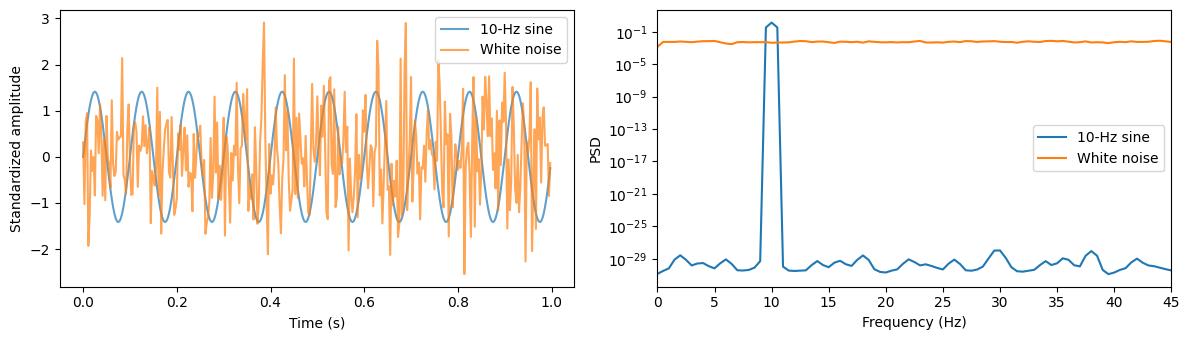

In [ ]:
rng = np.random.default_rng(42)
synthetic_t = np.arange(int(30*demo_fs)) / demo_fs
sine10 = np.sin(2*np.pi*10*synthetic_t)
noise = rng.normal(size=len(synthetic_t))
sine10 = (sine10-sine10.mean())/sine10.std()
noise = (noise-noise.mean())/noise.std()
synthetic_comparison = pd.DataFrame({
    name: {**time_features(z, demo_fs), **spectral_features(z, demo_fs)}
    for name, z in [('10-Hz sine', sine10), ('White noise', noise)]
}).T
display(synthetic_comparison[['rms_mV', 'hjorth_mobility_per_s',
                              'spectral_peak_hz', 'spectral_entropy_norm']]
        .rename(columns={'rms_mV': 'rms_unitless'}))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for name, z in [('10-Hz sine', sine10), ('White noise', noise)]:
    ax[0].plot(synthetic_t[:360], z[:360], label=name, alpha=.7)
    ff, pp = psd_estimate(z, demo_fs)
    ax[1].semilogy(ff, pp, label=name)
ax[0].set(xlabel='Time (s)', ylabel='Standardized amplitude')
ax[1].set(xlim=(0, 45), xlabel='Frequency (Hz)', ylabel='PSD')
for a in ax: a.legend()
plt.tight_layout(); plt.show()

## 4. 시간–주파수 특징

### 4-1. STFT를 그림 대신 숫자 표로 요약하기

STFT의 각 시간 프레임에서 $|Z(f,t)|^2$를 계산하고 주파수 대역별로 합산합니다. 프레임마다 대역 간 비율을 구한 다음, 시간축 평균과 표준편차를 특징으로 만듭니다.

- 평균: 그 대역이 전체적으로 차지하는 비중
- 표준편차: 그 비중이 시간에 따라 바뀌는 정도

전체 기록의 평균 PSD만 보면 잠깐 발생한 변화가 희석될 수 있습니다. 시간축 변동성을 추가하면 다른 관점의 정보를 담을 수 있습니다.

여기서는 **1초 Hann 창, 0.25초 hop**을 사용합니다. `boundary=None, padded=False`로 인공적인 양 끝 패딩을 만들지 않습니다. STFT 대역값은 상대 비율이며 앞의 Welch 절대 파워와 수치적으로 같은 양은 아닙니다.

In [ ]:
def stft_features(segment, fs):
    z = validate_segment(segment, fs)
    n = int(round(fs))
    freq, times, zz = signal.stft(z, fs=fs, window='hann', nperseg=n,
                                 noverlap=n-int(round(.25*fs)),
                                 boundary=None, padded=False)
    power = np.abs(zz)**2
    total = power[(freq >= .5) & (freq <= 40)].sum(axis=0)
    out = {}
    for name, (lo, hi) in ECG_BANDS.items():
        # 이산 빈이 두 대역에 중복 배정되지 않도록 마지막 대역만 상단 포함
        mask = (freq >= lo) & ((freq <= hi) if hi == 40 else (freq < hi))
        relative = np.divide(power[mask].sum(axis=0), total,
                             out=np.full(total.shape, np.nan), where=total > 1e-24)
        valid = relative[np.isfinite(relative)]
        out[f'stft_rel_{name}_mean'] = float(valid.mean()) if len(valid) else np.nan
        out[f'stft_rel_{name}_std'] = float(valid.std()) if len(valid) else np.nan
    return out

display(pd.Series(stft_features(first30, demo_fs)))

,0
stft_rel_0p5_5_mean,0.206077
stft_rel_0p5_5_std,0.153907
stft_rel_5_15_mean,0.423928
stft_rel_5_15_std,0.071002
stft_rel_15_40_mean,0.369995
stft_rel_15_40_std,0.102018


### 4-2. 웨이블릿: 여러 시간 규모의 에너지

이산 웨이블릿 변환은 신호를 느린 성분 A와 빠른 세부 성분 D로 나누는 과정을 반복합니다. 여기서는 `db4`, 5단계 분해를 사용합니다.

360 Hz일 때 대략적인 D1–D5 대역은 각각 90–180, 45–90, 22.5–45, 11.25–22.5, 5.625–11.25 Hz이고 A5는 0–5.625 Hz에 해당합니다. 실제 필터 응답은 겹치므로 날카로운 대역 분할은 아닙니다. 이미 40 Hz 저역통과한 신호라 D1·D2의 에너지는 작을 수 있습니다.

성분별 $E_j=\sum_k c_{j,k}^2$를 계산하고 $E_j/\sum_l E_l$로 정규화합니다. 전체 진폭보다 **에너지가 어떤 시간 규모에 분포하는지**를 봅니다. `periodization` 경계 확장을 사용하므로 끝부분과 시작부분의 접합에 의한 영향도 있을 수 있습니다.

,0
wavelet_db4_A5_rel_energy,0.190313
wavelet_db4_D5_rel_energy,0.257997
wavelet_db4_D4_rel_energy,0.382304
wavelet_db4_D3_rel_energy,0.161397
wavelet_db4_D2_rel_energy,0.007912
wavelet_db4_D1_rel_energy,0.000077


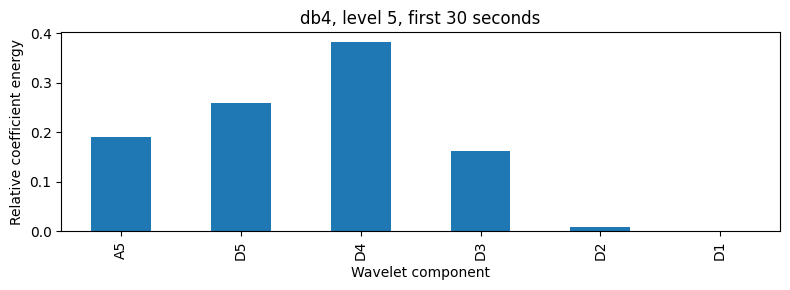

In [ ]:
def wavelet_features(segment, fs):
    z = validate_segment(segment, fs)
    wavelet = pywt.Wavelet('db4')
    if pywt.dwt_max_level(len(z), wavelet.dec_len) < 5:
        raise ValueError('db4 5단계 분해에 충분한 길이가 필요합니다.')
    coeffs = pywt.wavedec(z, wavelet, mode='periodization', level=5)
    names = ['A5', 'D5', 'D4', 'D3', 'D2', 'D1']
    energy = np.array([np.sum(c*c) for c in coeffs], dtype=float)
    relative = energy/energy.sum() if energy.sum() > 1e-24 else np.full(6, np.nan)
    return {f'wavelet_db4_{name}_rel_energy': float(value)
            for name, value in zip(names, relative)}

wavelet_example = pd.Series(wavelet_features(first30, demo_fs))
display(wavelet_example)
wavelet_example.rename(lambda name: name.split('_')[2]).plot.bar(figsize=(8, 3))
plt.ylabel('Relative coefficient energy'); plt.xlabel('Wavelet component')
plt.title('db4, level 5, first 30 seconds'); plt.tight_layout(); plt.show()

## 5. R파 검출과 RR 간격 특징

### 5-1. 정답 주석과 자동 검출을 구분하기

WFDB의 **XQRS**로 박동 위치를 자동 검출합니다. 이 실습에서 사용하는 인덱스는 QRS 검출기의 대표 위치이며 모든 박동의 정확한 양의 R파 꼭짓점과 일치하지 않을 수 있습니다.

`atr`에는 박동 종류뿐 아니라 리듬 변화 등 다른 표식도 있습니다. 따라서 `ann.sample` 전체를 RR 계산에 바로 쓰면 안 됩니다. 아래에서는 박동 표식만 골라 **그림의 비교 기준**으로 사용하고, 특징은 자동 검출 위치로 계산합니다.

정답 주석에서 얻은 위치를 입력 특징 계산에 쓰면 새 환자에게 주석이 없는 실제 운용 조건과 달라집니다. 주석을 쓰는 실험은 별도로 '정답 위치를 제공한 조건'이라고 밝혀야 합니다.

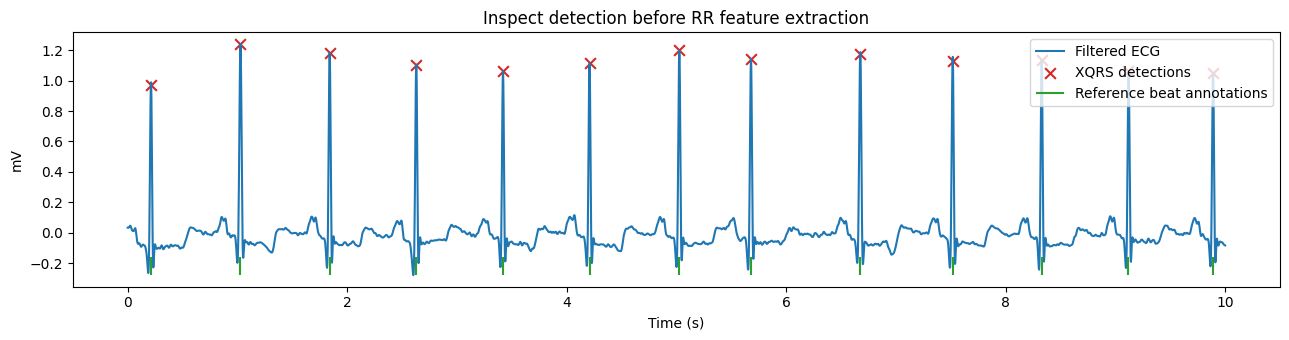

자동 검출: 223 개 / 기준 박동 표식: 223 개


In [ ]:
detected_peaks = processing.xqrs_detect(sig=demo_ecg, fs=demo_fs, verbose=False)
BEAT_SYMBOLS = {'N', 'L', 'R', 'B', 'A', 'a', 'J', 'S', 'V', 'r', 'F', 'e', 'j', 'n', 'E', '/', 'f', 'Q', '?'}
reference_beats = np.asarray([s for s, symbol in zip(demo_ann.sample, demo_ann.symbol)
                              if symbol in BEAT_SYMBOLS and s < len(demo_ecg)], dtype=int)
view_stop = int(10 * demo_fs)
dp = detected_peaks[detected_peaks < view_stop]
rp = reference_beats[reference_beats < view_stop]
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(demo_time[:view_stop], demo_ecg[:view_stop], label='Filtered ECG')
ax.scatter(dp/demo_fs, demo_ecg[dp], marker='x', s=60, color='tab:red', label='XQRS detections')
ax.vlines(rp/demo_fs, demo_ecg[:view_stop].min(), demo_ecg[:view_stop].min()+.12,
          color='tab:green', label='Reference beat annotations')
ax.set(xlabel='Time (s)', ylabel='mV', title='Inspect detection before RR feature extraction')
ax.legend(loc='upper right'); plt.tight_layout(); plt.show()
print('자동 검출:', len(detected_peaks), '개 / 기준 박동 표식:', len(reference_beats), '개')

### 5-2. RR 변동과 정상 박동 HRV는 같은 말이 아니다

검출 시점을 $t_i$라고 할 때 $RR_i=t_{i+1}-t_i$입니다.

$$\mathrm{RMSSD}_{RR}=\sqrt{\mathrm{mean}[(RR_{i+1}-RR_i)^2]}.$$

여기서는 자동 검출한 **모든 RR 간격**의 평균·표준편차·CV·RMSSD와 인접 RR 차이가 50 ms를 넘는 비율을 계산합니다. 부정맥과 검출 오류가 섞일 수 있으므로 변수명을 `sd_rr_ms`, `rmssd_rr_ms`, `pnn50_rr_pct`로 명시합니다.

정상 동성 박동의 **NN 간격을 검토·보정한 HRV 분석**과 구분합니다. 이 값들을 곧바로 SDNN·자율신경 기능으로 해석하지 않습니다. 30초 구간의 RR 표준편차를 24시간 SDNN의 임상 기준과 비교해서도 안 됩니다. LF/HF 등 장시간·전처리 조건에 민감한 HRV는 이 짧은 실습에서 계산하지 않습니다.

박동이 부족하면 통계가 불안정합니다. 코드에서는 RR 간격이 3개 미만이면 요약값을 `NaN`으로 두고 개수만 남깁니다. 이는 교육용 최소 조건이며 임상적 신뢰성을 보증하는 기준이 아닙니다. 극단적 간격도 자동 삭제하지 않고 먼저 파형을 확인합니다.

,0
n_rpeaks,223.000000
n_rr,222.000000
rr_mean_s,0.807120
sd_rr_ms,30.196724
rr_cv,0.037413
rmssd_rr_ms,38.008052
pnn50_rr_pct,4.524887
mean_hr_from_rr_bpm,74.338423


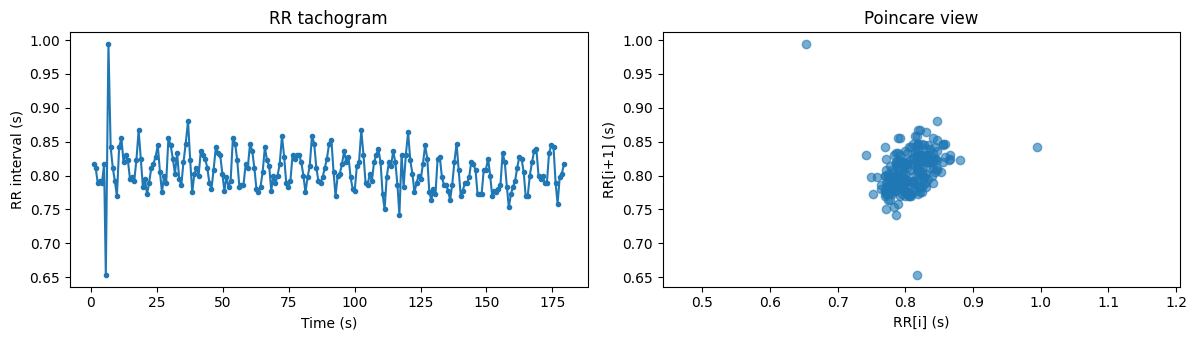

In [ ]:
def rr_features(peaks, fs):
    peaks = np.asarray(peaks, dtype=float)
    if peaks.ndim != 1 or not np.isfinite(peaks).all() or (np.diff(peaks) <= 0).any():
        raise ValueError('박동 인덱스는 1차원이며 유한하고 오름차순이어야 합니다.')
    rr = np.diff(peaks) / fs
    out = {'n_rpeaks': int(len(peaks)), 'n_rr': int(len(rr))}
    keys = ['rr_mean_s', 'sd_rr_ms', 'rr_cv', 'rmssd_rr_ms', 'pnn50_rr_pct', 'mean_hr_from_rr_bpm']
    if len(rr) < 3:
        out.update(dict.fromkeys(keys, np.nan))
        return out
    dr = np.diff(rr)
    out.update({
        'rr_mean_s': float(rr.mean()),
        'sd_rr_ms': float(1000*np.std(rr, ddof=1)),
        'rr_cv': float(np.std(rr, ddof=1)/rr.mean()),
        'rmssd_rr_ms': float(1000*np.sqrt(np.mean(dr**2))),
        'pnn50_rr_pct': float(100*np.mean(np.abs(dr) > .050)),
        'mean_hr_from_rr_bpm': float(60/rr.mean()),
    })
    return out

display(pd.Series(rr_features(detected_peaks, demo_fs)))
rr_s = np.diff(detected_peaks) / demo_fs
rr_time = detected_peaks[1:] / demo_fs
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
axs[0].plot(rr_time, rr_s, '.-')
axs[0].set(xlabel='Time (s)', ylabel='RR interval (s)', title='RR tachogram')
axs[1].scatter(rr_s[:-1], rr_s[1:], alpha=.6)
axs[1].set(xlabel='RR[i] (s)', ylabel='RR[i+1] (s)', title='Poincare view')
axs[1].set_aspect('equal', adjustable='datalim')
plt.tight_layout(); plt.show()

## 6. 박동 형태 특징: 기준점에 맞춘 유사도

박동을 검출 기준점에 맞춰 앞 0.2초, 뒤 0.4초씩 잘라 겹쳐 봅니다. 여러 박동의 **중앙값 템플릿**을 만든 뒤 각 박동과의 상관계수를 계산합니다.

- 평균 상관이 높음: 정렬된 박동들이 템플릿과 비슷함
- 상관의 변동이 큼: 서로 다른 형태·잡음·검출 위치의 차이가 섞일 가능성

이는 '정상 박동 점수'가 아닙니다. 규칙적인 비정상 파형도 서로 유사할 수 있습니다. P파·QRS 시작과 끝을 정밀 검출하지 않으므로 **QRS 폭이나 QT 간격을 계산했다고 주장하지 않습니다.**

구간 끝에서 잘린 박동은 제외합니다. 아래 특징은 해당 구간에서 자체 템플릿을 만들며 다른 환자나 시험 데이터의 정보를 사용하지 않습니다.

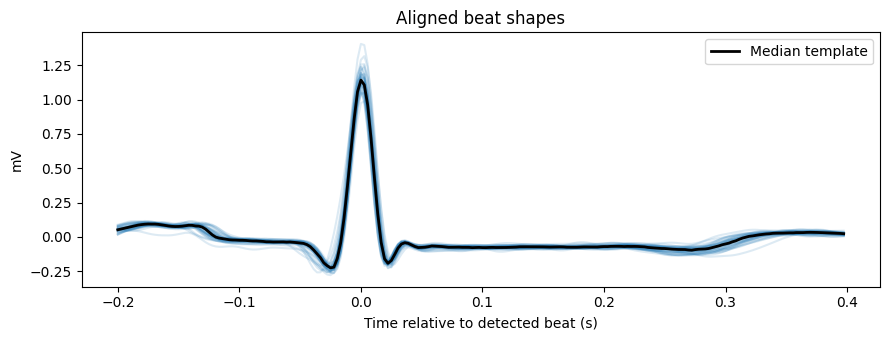

,0
n_complete_beats,37.000000
beat_template_corr_mean,0.990749
beat_template_corr_std,0.006965


In [ ]:
def aligned_beats(segment, peaks, fs):
    z = np.asarray(segment, dtype=float)
    left, right = int(round(.2*fs)), int(round(.4*fs))
    valid = [int(p) for p in peaks if p >= left and p+right <= len(z)]
    return (np.stack([z[p-left:p+right] for p in valid]) if valid
            else np.empty((0, left+right)))

def morphology_features(segment, peaks, fs):
    beats = aligned_beats(segment, peaks, fs)
    out = {'n_complete_beats': int(len(beats))}
    if len(beats) < 3:
        out.update({'beat_template_corr_mean': np.nan, 'beat_template_corr_std': np.nan})
        return out
    template = np.median(beats, axis=0)
    correlations = np.array([np.corrcoef(b, template)[0, 1]
                             for b in beats if np.std(b) > 1e-12 and np.std(template) > 1e-12])
    out.update({'beat_template_corr_mean': float(correlations.mean()) if len(correlations) else np.nan,
                'beat_template_corr_std': float(correlations.std()) if len(correlations) else np.nan})
    return out

peaks30 = detected_peaks[detected_peaks < len(first30)]
beats30 = aligned_beats(first30, peaks30, demo_fs)
if len(beats30):
    beat_t = (np.arange(beats30.shape[1])-int(round(.2*demo_fs)))/demo_fs
    fig, ax = plt.subplots(figsize=(9, 3.5))
    ax.plot(beat_t, beats30.T, color='tab:blue', alpha=.15)
    ax.plot(beat_t, np.median(beats30, axis=0), color='black', lw=2, label='Median template')
    ax.set(xlabel='Time relative to detected beat (s)', ylabel='mV', title='Aligned beat shapes')
    ax.legend(); plt.tight_layout(); plt.show()
display(pd.Series(morphology_features(first30, peaks30, demo_fs)))

## 7. 모든 특징을 구간별 표로 모으기

**30초 창, 15초 hop**으로 각 특징을 계산합니다. 창 안에 완전히 포함된 검출 시점만 골라 RR 간격을 구하므로 창 경계에 걸친 RR 쌍은 제외됩니다. 끝에 남는 30초 미만 구간도 제외합니다.

`record`, `split`, `window_start_s` 등의 관리 정보와 실제 특징 열을 분리합니다. 관리 정보를 아무 생각 없이 모델에 넣으면 환자·기록·분할을 외울 수 있습니다.

특징이 `NaN`이면 '0'과 다릅니다. 상수 신호·부족한 박동 등으로 정의하지 못한 값일 수 있으므로 원인을 확인한 후 훈련 데이터 기준으로 처리합니다. 파형 품질을 판정하는 검증된 규칙을 이 실습에서 임의로 만들지는 않습니다.

In [ ]:
def feature_table(ecg, peaks, fs, record_id, split_name, window_s=30, hop_s=15):
    z = validate_segment(ecg, fs)
    if window_s < 2 or hop_s <= 0:
        raise ValueError('window_s >= 2, hop_s > 0 조건이 필요합니다.')
    width, hop = int(round(window_s*fs)), int(round(hop_s*fs))
    if hop < 1:
        raise ValueError('hop이 1표본 이상이어야 합니다.')
    rows = []
    for start in range(0, len(z)-width+1, hop):
        end = start+width
        segment = z[start:end]
        local_peaks = peaks[(peaks >= start) & (peaks < end)]-start
        row = {'record': str(record_id), 'split': split_name,
               'window_start_s': start/fs, 'window_end_s': end/fs}
        for values in [time_features(segment, fs), spectral_features(segment, fs),
                       stft_features(segment, fs), wavelet_features(segment, fs),
                       rr_features(local_peaks, fs), morphology_features(segment, local_peaks, fs)]:
            row.update(values)
        rows.append(row)
    return pd.DataFrame(rows)

features = feature_table(demo_ecg, detected_peaks, demo_fs, DEMO_RECORD, 'train')
META_COLUMNS = ['record', 'split', 'window_start_s', 'window_end_s']
FEATURE_COLUMNS = [c for c in features.columns if c not in META_COLUMNS]
X_demo = features[FEATURE_COLUMNS].copy()
print(f'구간 수={len(features)}, 특징 수={len(FEATURE_COLUMNS)}')
display(features.head())
display(features[FEATURE_COLUMNS].isna().sum().rename('missing_count').loc[lambda s: s > 0])

구간 수=11, 특징 수=46


,record,split,window_start_s,window_end_s,mean_mV,std_mV,rms_mV,iqr_mV,peak_to_peak_mV,skewness,...,n_rr,rr_mean_s,sd_rr_ms,rr_cv,rmssd_rr_ms,pnn50_rr_pct,mean_hr_from_rr_bpm,n_complete_beats,beat_template_corr_mean,beat_template_corr_std
0,100,train,0.0,30.0,-0.000559,0.166653,0.166654,0.089331,1.684544,4.892048,...,36,0.811265,47.596298,0.058669,74.375709,14.285714,73.958531,37,0.990749,0.006965
1,100,train,15.0,45.0,0.000421,0.169727,0.169727,0.088615,1.692697,4.864086,...,36,0.814043,26.268056,0.032269,29.758730,5.714286,73.706161,36,0.990242,0.007425
2,100,train,30.0,60.0,0.000054,0.167067,0.167067,0.087650,1.613442,4.850912,...,36,0.812423,24.973408,0.030739,27.244889,5.714286,73.853167,37,0.990029,0.007362
3,100,train,45.0,75.0,-0.000309,0.166172,0.166172,0.087066,1.742390,4.893922,...,36,0.809259,24.702819,0.030525,25.271890,2.857143,74.141876,36,0.990225,0.007610
4,100,train,60.0,90.0,-0.000050,0.167726,0.167726,0.087934,1.742390,4.864373,...,36,0.809877,23.006445,0.028407,22.819358,0.000000,74.085366,37,0.990270,0.004789


,missing_count


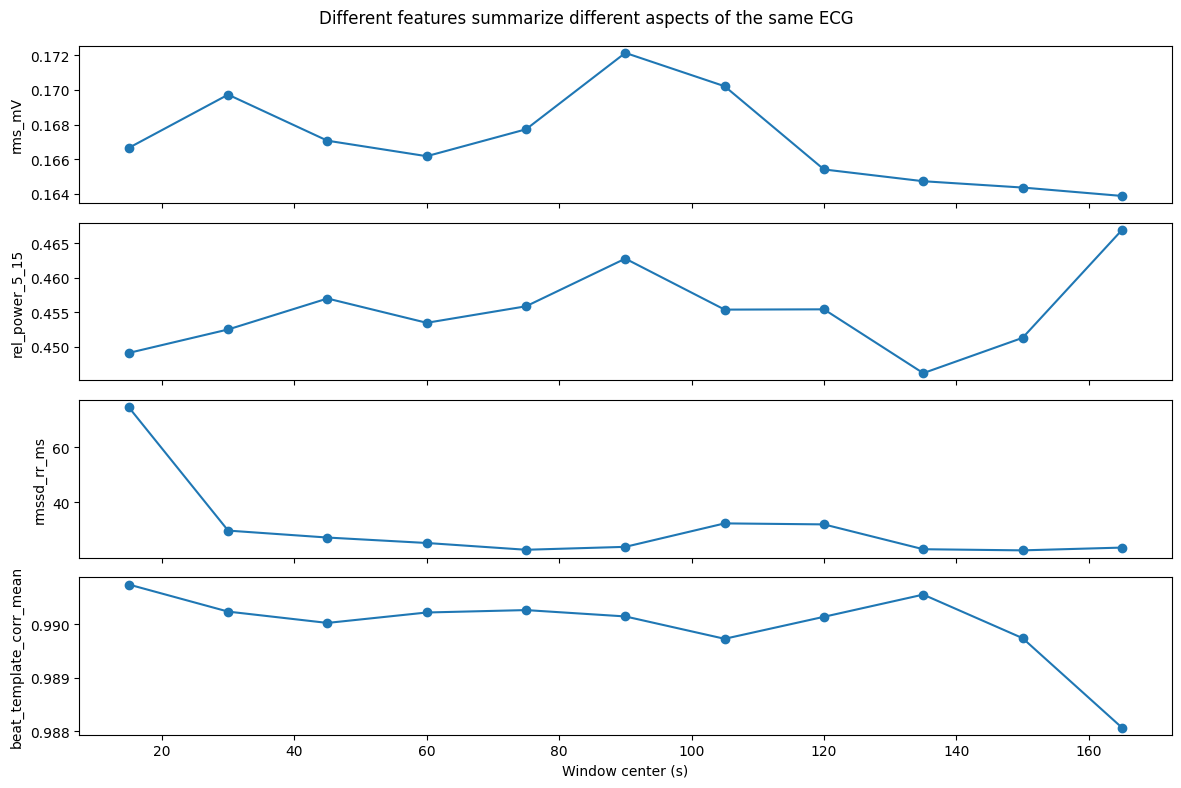

실행하면 생성되는 파일: /content/results/ecg_feature_demo.csv


In [ ]:
plot_columns = ['rms_mV', 'rel_power_5_15', 'rmssd_rr_ms', 'beat_template_corr_mean']
fig, axs = plt.subplots(len(plot_columns), 1, figsize=(12, 8), sharex=True)
centers = (features['window_start_s']+features['window_end_s'])/2
for ax, name in zip(axs, plot_columns):
    ax.plot(centers, features[name], 'o-')
    ax.set_ylabel(name)
axs[-1].set_xlabel('Window center (s)')
plt.suptitle('Different features summarize different aspects of the same ECG')
plt.tight_layout(); plt.show()

RESULTS.mkdir(parents=True, exist_ok=True)
feature_csv = RESULTS / 'ecg_feature_demo.csv'
features.to_csv(feature_csv, index=False)
feature_settings = {'record': DEMO_RECORD, 'fs_hz': demo_fs, 'unit': demo_unit,
    'duration_s': len(demo_ecg)/demo_fs, 'window_s': 30, 'hop_s': 15,
    'filter': '4th-order Butterworth 0.5-40 Hz, sosfiltfilt, offline',
    'psd': 'Welch, Hann 2s, 50% overlap, density',
    'stft': 'Hann 1s, hop 0.25s, no boundary padding',
    'wavelet': 'db4, level 5, periodization',
    'beat_detector': 'WFDB XQRS, automatic, no annotation-derived input',
    'rr_note': 'all detected RR, not curated NN HRV',
    'feature_columns': FEATURE_COLUMNS}
(RESULTS/'ecg_feature_settings.json').write_text(json.dumps(feature_settings, ensure_ascii=False, indent=2))
print('실행하면 생성되는 파일:', feature_csv)

## 8. 정규화와 특징 중복을 직접 확인하기

### 8-1. 구간별 z-score와 특징별 표준화

**파형 구간별 z-score**는 한 구간의 평균을 빼고 그 구간의 표준편차로 나눕니다. 그 후 표준편차와 Activity를 계산하면 거의 1이므로 원래 진폭 차이는 사라집니다.

반면 **특징별 표준화**는 RMS 열, RR 열 등 각 열을 훈련 데이터의 평균·표준편차로 변환하는 작업입니다. 서로 다른 구간의 상대적인 크기 순서는 보존합니다. 두 작업은 서로 다릅니다.

In [ ]:
z30 = (first30-first30.mean())/first30.std()
normalization_demo = pd.DataFrame({
    'physical mV': time_features(first30, demo_fs),
    'per-window z-score (unitless)': time_features(z30, demo_fs),
})
# 함수의 열 이름은 물리 mV 입력 기준입니다. 두 번째 열은 단위가 없는 설명용 비교입니다.
display(normalization_demo.loc[['mean_mV','std_mV','rms_mV','hjorth_activity_mV2',
                                'hjorth_mobility_per_s','hjorth_complexity']])

,physical mV,per-window z-score (unitless)
mean_mV,-0.000559,2.960595e-18
std_mV,0.166653,1.000000e+00
rms_mV,0.166654,1.000000e+00
hjorth_activity_mV2,0.027773,1.000000e+00
hjorth_mobility_per_s,96.598338,9.659834e+01
hjorth_complexity,1.463865,1.463865e+00


### 8-2. 특징을 많이 계산했다고 정보가 모두 새로워지는 것은 아니다

표준편차와 RMS, Activity는 수학적으로 강하게 연결됩니다. 아래 상관행렬은 중복을 살펴보는 **탐색용 그림**입니다.

현재는 한 사람의 겹치는 창 11개뿐입니다. 상관계수를 일반적인 생리학적 법칙으로 해석하거나, 이 그림으로 임상 결론을 내리지 않습니다. 특징 선택을 한다면 환자 단위 교차검증의 각 훈련 fold 안에서 수행합니다.

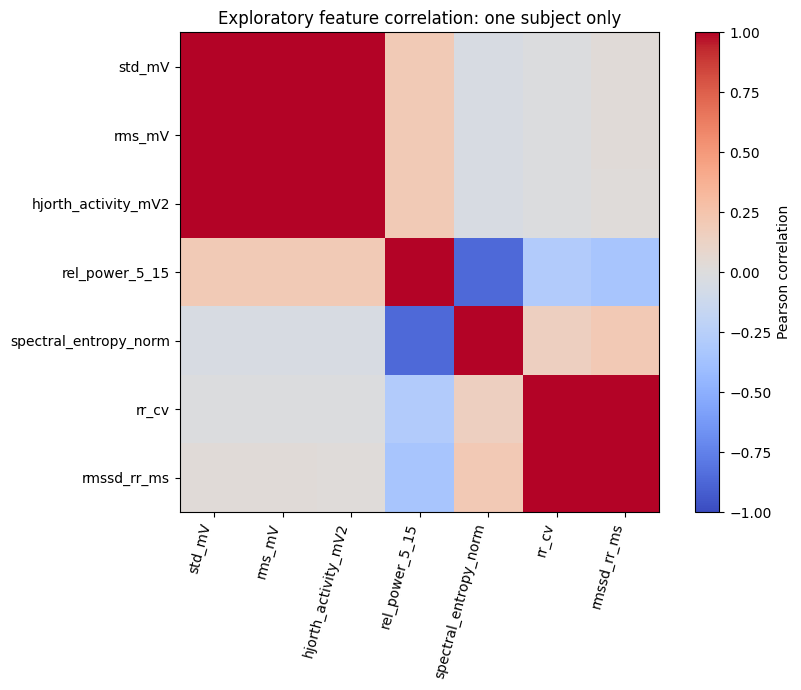

In [ ]:
corr_columns = ['std_mV', 'rms_mV', 'hjorth_activity_mV2', 'rel_power_5_15',
                'spectral_entropy_norm', 'rr_cv', 'rmssd_rr_ms']
corr = features[corr_columns].corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(corr_columns)), corr_columns, rotation=75, ha='right')
ax.set_yticks(range(len(corr_columns)), corr_columns)
fig.colorbar(im, ax=ax, label='Pearson correlation')
ax.set_title('Exploratory feature correlation: one subject only')
plt.tight_layout(); plt.show()

## 9. 다음 실습: ML에 연결하는 방법

현재는 특징 계산을 설명하기 위해 **한 훈련 기록의 3분**을 사용했습니다. 이 표만 무작위 분할해 높은 성능을 보고해도 새 환자 일반화를 검증한 것이 아닙니다.

다음 실습에서는 기존 `SPLITS`의 기록을 각각 처리하고, 같은 환자의 모든 창을 같은 분할에 유지합니다. MIT-BIH의 201·202는 같은 사람의 기록이므로 전체 데이터로 확장할 때 같은 그룹으로 묶어야 합니다.

1. 예측 과제와 정답 단위를 정합니다. '박동 종류', '30초 창의 특정 사건 포함 여부', '환자 진단'은 서로 다른 과제입니다.
2. 기록·환자별로 train/validation/test를 분리합니다.
3. 훈련에서만 결측 대체·특징별 표준화·특징 선택을 학습합니다.
4. Logistic Regression 또는 Random Forest로 기준 성능을 확인합니다.
5. XGBoost·CatBoost 등과 비교하고, 환자 단위 결과와 불균형 지표를 확인합니다.

`ann`에서 만든 정답은 **y로만 관리**하고 특징 X에 섞지 않습니다. 정답 박동 종류를 알아야 계산할 수 있는 특징은 실제 사용 조건을 따로 밝혀야 합니다. 이 노트북은 임상 진단 라벨을 임의로 만들어 분류기를 학습하지 않습니다.

## 참고 자료

- MIT-BIH Arrhythmia Database: https://physionet.org/content/mitdb/1.0.0/
- WFDB 신호처리와 XQRS: https://wfdb.readthedocs.io/en/latest/processing.html
- SciPy Welch PSD: https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.welch.html
- PyWavelets DWT: https://pywavelets.readthedocs.io/en/latest/ref/dwt-discrete-wavelet-transform.html
- Zabihi et al. (2017), ECG 특징과 Random Forest: https://www.cinc.org/archives/2017/pdf/069-336.pdf
- Zabihi et al. (2023), EEG·ECG 특징과 HyperEnsemble: https://www.cinc.org/archives/2023/pdf/CinC2023-142.pdf

이 노트북의 특징 묶음은 교육용 예시입니다. 위 대회 모형을 완전히 재현한 코드가 아닙니다. 필터·주파수 경계·창 길이·정규화·박동 처리 규칙이 바뀌면 특징 값도 달라집니다.